# Obesity Levels: What Do Habits and Body Measures Really Tell Us?

**Scientific Data Visualisation project** · dataset: *Estimation of Obesity Levels Based on Eating Habits and Physical Condition* (UCI, Palechor & de la Hoz Manotas, 2019), 2,111 people from Mexico, Peru and Colombia.

**The story we tell**

1. *What is in the data?* A balanced, partly synthetic sample, not a picture of real obesity prevalence.
2. *What is the target?* The obesity level is a **label derived from BMI**, so height and weight "explain" it by construction.
3. *What do habits add?* We ask how much of the obesity level can be told from eating habits, activity, age and gender alone, once height and weight are removed.

**How the figures are designed** (the course principles, applied consistently)

| Principle | What we do |
|---|---|
| Colour carries one meaning | Blue = main data, orange = second category (always with a legend), grey = context. The 7 obesity levels always use the same ordered colours: blue (underweight) → grey (normal) → light-to-dark orange (overweight to obesity III). |
| Gestalt: similarity, proximity, common region | Same level = same colour everywhere; small multiples share axes; related panels sit next to each other. |
| Direct labels, no clutter | Values are written on bars/dots; light grid; no 3D, no pie charts, no dual axes. |
| Honest axes | Bars start at zero, uncertainty is shown (confidence intervals), sample sizes are printed. |
| Titles say the message | Each figure title states the finding; a subtitle line gives the method where needed. |

## 1. Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patheffects as pe
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.ticker import FuncFormatter, PercentFormatter
import seaborn as sns
from scipy import stats
import plotly.graph_objects as go
from IPython.display import HTML, display

from sklearn.manifold import TSNE
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix
from sklearn.model_selection import StratifiedKFold, cross_val_predict, train_test_split
from sklearn.neighbors import NearestNeighbors

# ---- paths: put the CSV next to the notebook or in data/raw/
FILE = "ObesityDataSet_raw_and_data_sinthetic.csv"
DATA_FILE = next((p for p in [Path(FILE), Path("data/raw") / FILE, Path("../data/raw") / FILE] if p.exists()), None)
assert DATA_FILE is not None, f"Put {FILE} next to the notebook or in data/raw/"
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)
SEED = 42
rng = np.random.default_rng(SEED)

# ---- colours (Okabe-Ito based, colour-blind safe)
BLUE, ORANGE, GREY, INK = "#0072B2", "#E69F00", "#BDBDBD", "#2B2B2B"
HALO = [pe.withStroke(linewidth=3, foreground="white")]

LEVELS = ["Insufficient_Weight", "Normal_Weight", "Overweight_Level_I", "Overweight_Level_II",
          "Obesity_Type_I", "Obesity_Type_II", "Obesity_Type_III"]
LEVEL_NAME = dict(zip(LEVELS, ["Insufficient", "Normal", "Overweight I", "Overweight II",
                               "Obesity I", "Obesity II", "Obesity III"]))
# ordered scale: blue (below normal) -> neutral grey (normal) -> light-to-dark orange/brown (above normal)
LEVEL_COLOR = dict(zip(LEVEL_NAME.values(),
                       ["#4C9BD5", "#B8B8B8", "#F2C879", "#E8A23D", "#D0701F", "#A5471A", "#6E2A10"]))
LEVEL_ORDER = list(LEVEL_NAME.values())

sns.set_theme(style="white", context="notebook")
plt.rcParams.update({
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": INK,
    "axes.labelcolor": INK, "text.color": INK, "xtick.color": INK, "ytick.color": INK,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": False, "figure.dpi": 110, "savefig.dpi": 200, "legend.frameon": False,
})

thousands = FuncFormatter(lambda x, _: f"{x:,.0f}")


def save(fig, name):
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight", facecolor="white")


def subtitle(ax, text, y=1.02):
    """grey method line under the title"""
    ax.text(0, y, text, transform=ax.transAxes, fontsize=9.5, color="#5A5A5A", va="bottom")


def show_plotly(fig):
    display(HTML(fig.to_html(include_plotlyjs="cdn", full_html=False)))

## 2. Load the data and understand what each column is

We read the file with `keep_default_na=False` so that the answer `no` is never confused with a missing value. Columns are renamed to readable names. The **codebook** below also corrects something easy to miss: the five "numeric" lifestyle columns are **ordinal codes of questionnaire answers** (for example `FAF` = 0, 1, 2, 3 for increasing physical activity), not litres, hours or days.

In [2]:
raw = pd.read_csv(DATA_FILE, keep_default_na=False, na_values=["NA", ""])

RENAME = {"Gender": "gender", "Age": "age", "Height": "height", "Weight": "weight",
          "family_history_with_overweight": "family_history", "FAVC": "high_cal_food",
          "FCVC": "veg_freq", "NCP": "main_meals", "CAEC": "snacking", "SMOKE": "smoke",
          "CH2O": "water", "SCC": "track_calories", "FAF": "activity", "TUE": "screen_time",
          "CALC": "alcohol", "MTRANS": "transport", "NObeyesdad": "level_raw"}
raw = raw.rename(columns=RENAME)

print("shape:", raw.shape, "| missing values:", int(raw.isna().sum().sum()),
      "| exact duplicate rows:", int(raw.duplicated().sum()))
display(raw.head())

codebook = pd.DataFrame([
    ("gender", "categorical", "Female / Male"),
    ("age", "numeric (years)", "14 to 61"),
    ("height, weight", "numeric (m, kg)", "used to compute BMI"),
    ("family_history", "yes/no", "family member with overweight"),
    ("high_cal_food", "yes/no", "frequently eats high-calorie food (FAVC)"),
    ("veg_freq", "ordinal code 1-3", "vegetables with meals: never, sometimes, always (FCVC)"),
    ("main_meals", "ordinal code 1-4", "number of main meals per day (NCP)"),
    ("snacking", "ordinal categories", "food between meals: no, Sometimes, Frequently, Always (CAEC)"),
    ("smoke", "yes/no", "smokes"),
    ("water", "ordinal code 1-3", "daily water: low to high (CH2O)"),
    ("track_calories", "yes/no", "monitors calorie intake (SCC)"),
    ("activity", "ordinal code 0-3", "physical activity: none to most frequent (FAF)"),
    ("screen_time", "ordinal code 0-2", "time on devices: short to long (TUE)"),
    ("alcohol", "ordinal categories", "no, Sometimes, Frequently, Always (CALC)"),
    ("transport", "categorical", "Public transport, Automobile, Walking, Motorbike, Bike (MTRANS)"),
    ("level_raw", "target (7 classes)", "obesity level label; derived from BMI (see section 5)"),
], columns=["column", "type", "meaning"]).set_index("column")
display(codebook)

shape: (2111, 17) | missing values: 0 | exact duplicate rows: 24


,gender,age,height,weight,family_history,high_cal_food,veg_freq,main_meals,snacking,smoke,water,track_calories,activity,screen_time,alcohol,transport,level_raw
0,Female,21.0,1.62,64.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,0.0,1.0,no,Public_Transportation,Normal_Weight
1,Female,21.0,1.52,56.0,yes,no,3.0,3.0,Sometimes,yes,3.0,yes,3.0,0.0,Sometimes,Public_Transportation,Normal_Weight
2,Male,23.0,1.80,77.0,yes,no,2.0,3.0,Sometimes,no,2.0,no,2.0,1.0,Frequently,Public_Transportation,Normal_Weight
3,Male,27.0,1.80,87.0,no,no,3.0,3.0,Sometimes,no,2.0,no,2.0,0.0,Frequently,Walking,Overweight_Level_I
4,Male,22.0,1.78,89.8,no,no,2.0,1.0,Sometimes,no,2.0,no,0.0,0.0,Sometimes,Public_Transportation,Overweight_Level_II


,type,meaning
column,,
gender,categorical,Female / Male
age,numeric (years),14 to 61
"height, weight","numeric (m, kg)",used to compute BMI
family_history,yes/no,family member with overweight
high_cal_food,yes/no,frequently eats high-calorie food (FAVC)
veg_freq,ordinal code 1-3,"vegetables with meals: never, sometimes, alway..."
main_meals,ordinal code 1-4,number of main meals per day (NCP)
snacking,ordinal categories,"food between meals: no, Sometimes, Frequently,..."
smoke,yes/no,smokes


## 3. Data quality: what kind of data is this?

Three checks before any analysis: missing values, duplicates, and whether the values look like real survey answers. The UCI page states that **77% of the rows were generated synthetically (SMOTE) and only 23% were collected from real respondents**. The file has no flag for which rows are real, but synthetic rows leave fingerprints: ordinal questionnaire codes that should be whole numbers contain fractions, and ages have many decimals.

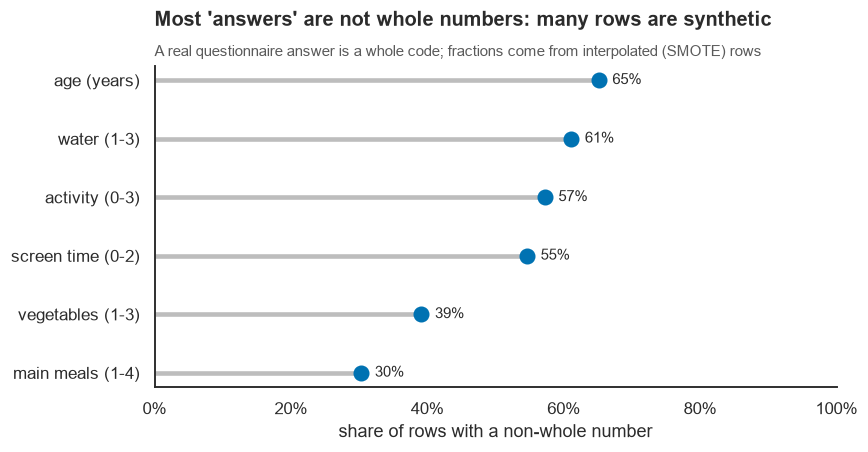

Duplicate rows: 24 (1.1%), removed below so that every person counts once.


In [3]:
ord_cols = ["veg_freq", "main_meals", "water", "activity", "screen_time"]
frac = pd.Series({c: (raw[c] % 1 != 0).mean() for c in ord_cols + ["age"]}).sort_values()
nice = {"veg_freq": "vegetables (1-3)", "main_meals": "main meals (1-4)", "water": "water (1-3)",
        "activity": "activity (0-3)", "screen_time": "screen time (0-2)", "age": "age (years)"}

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hlines([nice[i] for i in frac.index], 0, frac.values, color=GREY, lw=3)
ax.scatter(frac.values, [nice[i] for i in frac.index], color=BLUE, s=90, zorder=3)
for y, v in enumerate(frac.values):
    ax.text(v + 0.02, y, f"{v:.0%}", va="center", fontsize=10)
ax.set_xlim(0, 1)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("share of rows with a non-whole number")
ax.set_title("Most 'answers' are not whole numbers: many rows are synthetic", pad=26)
subtitle(ax, "A real questionnaire answer is a whole code; fractions come from interpolated (SMOTE) rows", y=1.02)
save(fig, "01_synthetic_fingerprint")
plt.show()

n_dup = int(raw.duplicated().sum())
print(f"Duplicate rows: {n_dup} ({n_dup / len(raw):.1%}), removed below so that every person counts once.")

### 3.1 Cleaning decisions

* **Duplicates** are removed (they inflate counts and make distances zero for embeddings).
* **Ordinal codes** keep their original fractional value for numeric analysis and also get a **rounded whole-number copy** (`*_r`) for category-style plots.
* **BMI** = weight / height² is computed.
* **Rare categories are grouped** for comparisons (`Always` alcohol = 1 person; `Bike` = 7; `Motorbike` = 11), because percentages of tiny groups are meaningless.

In [4]:
df = raw.drop_duplicates().reset_index(drop=True).copy()
df["bmi"] = df.weight / df.height**2
df["level"] = pd.Categorical(df.level_raw.map(LEVEL_NAME), categories=LEVEL_ORDER, ordered=True)
df["obese"] = df.level.isin(["Obesity I", "Obesity II", "Obesity III"])      # label-based flag

for c in ord_cols:
    df[c + "_r"] = df[c].round().astype(int)

df["snacking"] = pd.Categorical(df.snacking, ["no", "Sometimes", "Frequently", "Always"], ordered=True)
df["alcohol"] = pd.Categorical(df.alcohol, ["no", "Sometimes", "Frequently", "Always"], ordered=True)
df["alcohol_g"] = df.alcohol.astype(str).replace({"Always": "Frequently/Always", "Frequently": "Frequently/Always"})
df["transport_g"] = df.transport.replace({"Bike": "Other (walk, bike, motorbike)",
                                          "Motorbike": "Other (walk, bike, motorbike)",
                                          "Walking": "Other (walk, bike, motorbike)",
                                          "Public_Transportation": "Public transport", "Automobile": "Car"})

print(f"{len(df):,} people after removing duplicates")
display(df[["age", "height", "weight", "bmi"] + ord_cols].describe().T.round(2))

2,087 people after removing duplicates


,count,mean,std,min,25%,50%,75%,max
age,2087.0,24.35,6.37,14.00,19.92,22.85,26.00,61.00
height,2087.0,1.70,0.09,1.45,1.63,1.70,1.77,1.98
weight,2087.0,86.86,26.19,39.00,66.00,83.10,108.02,173.00
bmi,2087.0,29.77,8.02,13.00,24.37,28.90,36.10,50.81
veg_freq,2087.0,2.42,0.53,1.00,2.00,2.40,3.00,3.00
main_meals,2087.0,2.70,0.76,1.00,2.70,3.00,3.00,4.00
water,2087.0,2.00,0.61,1.00,1.59,2.00,2.47,3.00
activity,2087.0,1.01,0.85,0.00,0.12,1.00,1.68,3.00
screen_time,2087.0,0.66,0.61,0.00,0.00,0.63,1.00,2.00


## 4. One variable at a time

### 4.1 Body measures and age

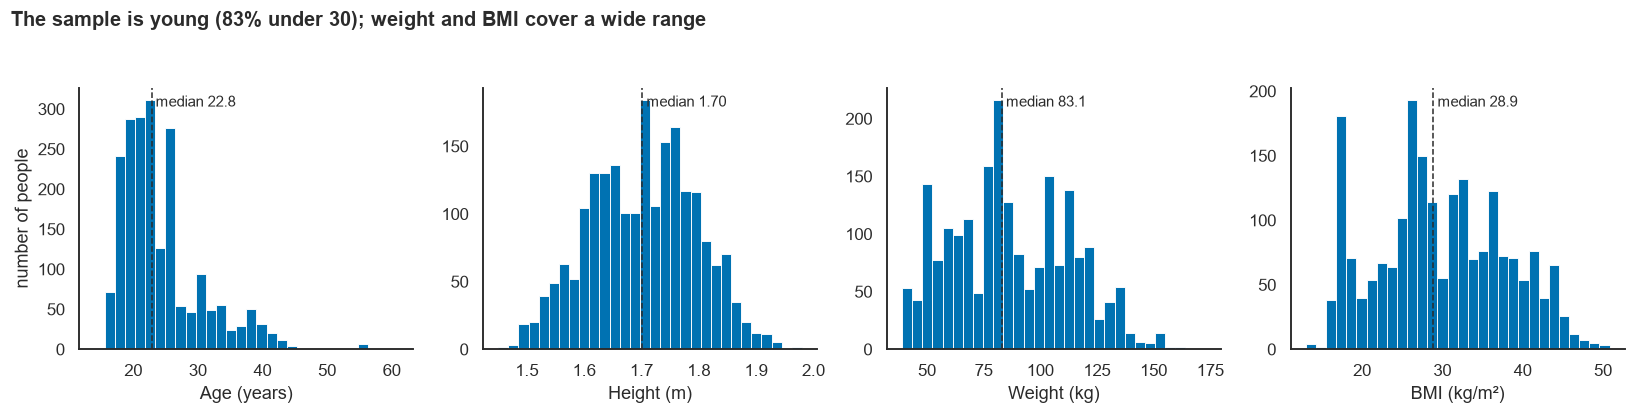

83% of the people are younger than 30; 2.7% are older than 40.


In [5]:
panels = [("age", "Age (years)"), ("height", "Height (m)"), ("weight", "Weight (kg)"), ("bmi", "BMI (kg/m²)")]
fig, axes = plt.subplots(1, 4, figsize=(15, 3.6))
for ax, (c, lab) in zip(axes, panels):
    ax.hist(df[c], bins=30, color=BLUE, edgecolor="white", linewidth=0.6)
    med = df[c].median()
    ax.axvline(med, color=INK, ls="--", lw=1)
    ax.text(med, ax.get_ylim()[1] * 0.97, f" median {med:.1f}" if c != "height" else f" median {med:.2f}",
            fontsize=9.5, va="top")
    ax.set_xlabel(lab)
    ax.yaxis.set_major_formatter(thousands)
axes[0].set_ylabel("number of people")
fig.suptitle(f"The sample is young ({(df.age < 30).mean():.0%} under 30); weight and BMI cover a wide range", x=0.01, ha="left",
             fontsize=13, fontweight="bold", y=1.04)
fig.tight_layout()
save(fig, "02_numeric_distributions")
plt.show()

print(f"{(df.age < 30).mean():.0%} of the people are younger than 30; {(df.age > 40).mean():.1%} are older than 40.")

### 4.2 Lifestyle scores (ordinal codes)

Bars show the share of people at each code. The scale is shared inside each panel and the bars start at zero.

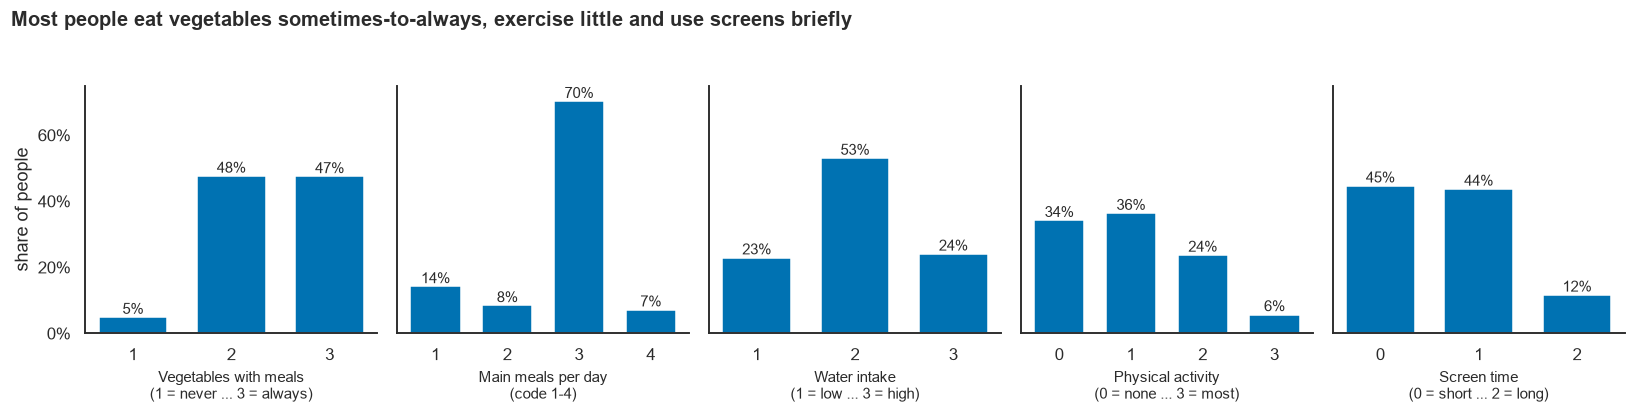

In [6]:
lab = {"veg_freq": "Vegetables with meals\n(1 = never ... 3 = always)", "main_meals": "Main meals per day\n(code 1-4)",
       "water": "Water intake\n(1 = low ... 3 = high)", "activity": "Physical activity\n(0 = none ... 3 = most)",
       "screen_time": "Screen time\n(0 = short ... 2 = long)"}
fig, axes = plt.subplots(1, 5, figsize=(15, 3.6), sharey=True)
for ax, c in zip(axes, ord_cols):
    share = df[c + "_r"].value_counts(normalize=True).sort_index()
    ax.bar(share.index.astype(str), share.values, color=BLUE, width=0.7)
    for x, v in enumerate(share.values):
        ax.text(x, v + 0.01, f"{v:.0%}", ha="center", fontsize=9.5)
    ax.set_xlabel(lab[c], fontsize=10)
    ax.set_ylim(0, 0.75)
axes[0].yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
axes[0].set_ylabel("share of people")
fig.suptitle("Most people eat vegetables sometimes-to-always, exercise little and use screens briefly",
             x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.04)
fig.tight_layout()
save(fig, "03_lifestyle_scores")
plt.show()

### 4.3 Categorical variables

Rare categories are visible here (Always alcohol, Bike, Motorbike), which is why section 3.1 groups them.

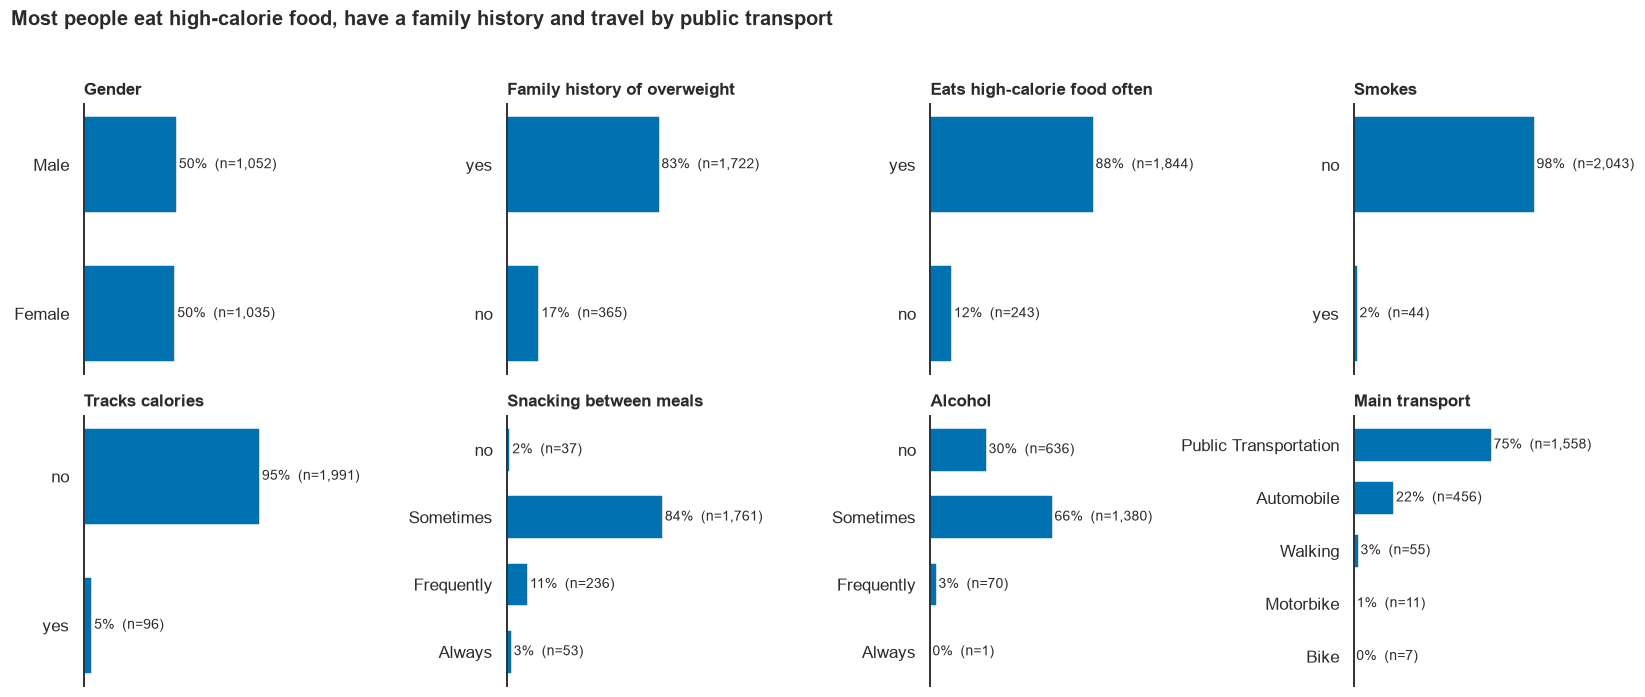

In [7]:
cat_vars = [("gender", "Gender", None), ("family_history", "Family history of overweight", None),
            ("high_cal_food", "Eats high-calorie food often", None), ("smoke", "Smokes", None),
            ("track_calories", "Tracks calories", None),
            ("snacking", "Snacking between meals", ["no", "Sometimes", "Frequently", "Always"]),
            ("alcohol", "Alcohol", ["no", "Sometimes", "Frequently", "Always"]),
            ("transport", "Main transport", None)]
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2))
for ax, (c, title, order) in zip(axes.ravel(), cat_vars):
    s = df[c].astype(str).str.replace("_", " ").value_counts()
    s = s.reindex(order) if order else s.sort_values(ascending=False)
    s = s[::-1]                                   # so that the first item is on top
    ax.barh(s.index, s.values / len(df), color=BLUE, height=0.65)
    for y, v in enumerate(s.values):
        ax.text(v / len(df) + 0.01, y, f"{v / len(df):.0%}  (n={v:,})", va="center", fontsize=9)
    ax.set_xlim(0, 1.25)
    ax.set_xticks([])
    ax.spines["bottom"].set_visible(False)
    ax.set_title(title, fontsize=11)
fig.suptitle("Most people eat high-calorie food, have a family history and travel by public transport",
             x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.02)
fig.tight_layout()
save(fig, "04_categorical_overview")
plt.show()

## 5. The target: obesity level

### 5.1 Class balance is an artefact of the data generation

In real populations, normal weight is far more common than Obesity III. Here every level has roughly 270-350 people because the synthetic oversampling balanced the classes. **Percentages of levels in this dataset must not be read as prevalence.**

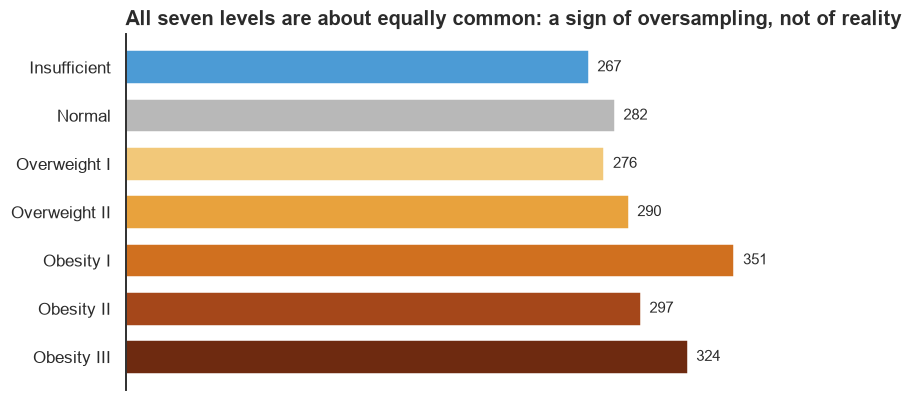

In [8]:
cnt = df.level.value_counts().reindex(LEVEL_ORDER)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.barh(cnt.index[::-1], cnt.values[::-1], color=[LEVEL_COLOR[l] for l in cnt.index[::-1]], height=0.7)
for y, v in enumerate(cnt.values[::-1]):
    ax.text(v + 5, y, f"{v:,}", va="center", fontsize=10)
ax.set_xlim(0, cnt.max() * 1.12)
ax.set_xticks([])
ax.spines["bottom"].set_visible(False)
ax.set_title("All seven levels are about equally common: a sign of oversampling, not of reality")
save(fig, "05_class_balance")
plt.show()

### 5.2 The label is built from BMI, but not perfectly

The dataset description says levels come from BMI cut-offs (below 18.5 insufficient, 18.5-24.9 normal, 25-29.9 overweight, 30-34.9 obesity I, 35-39.9 obesity II, 40 and above obesity III). The picture shows how well that holds. Dashed lines are the cut-offs; each dot is one person.

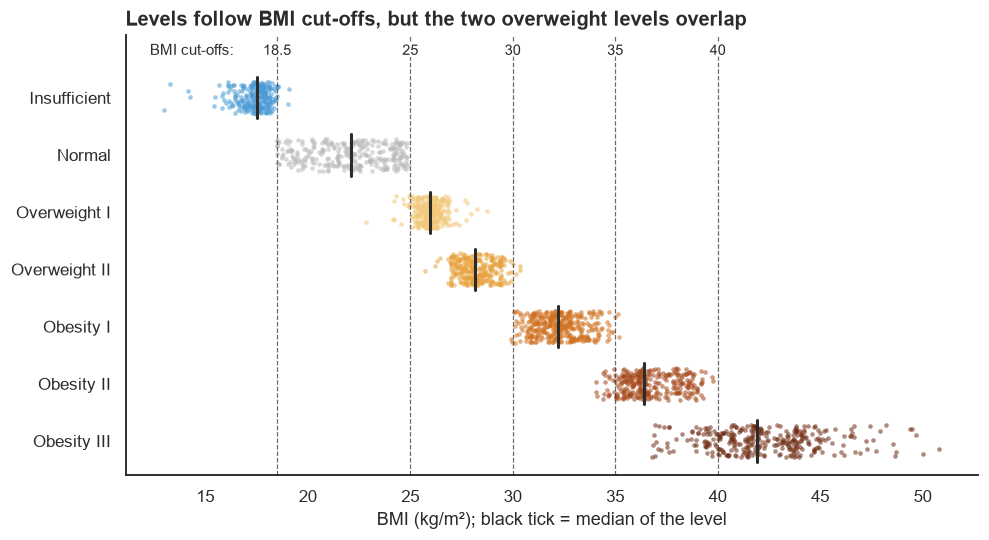

In [9]:
cuts = [18.5, 25, 30, 35, 40]
fig, ax = plt.subplots(figsize=(10, 5.2))
for k, lvl in enumerate(LEVEL_ORDER):
    d = df[df.level == lvl]
    y = k + rng.uniform(-0.28, 0.28, len(d))
    ax.scatter(d.bmi, y, s=9, color=LEVEL_COLOR[lvl], alpha=0.55, linewidths=0)
    ax.plot([d.bmi.median()] * 2, [k - 0.36, k + 0.36], color=INK, lw=2)
for c in cuts:
    ax.axvline(c, color=INK, ls="--", lw=0.8, alpha=0.7)
    ax.text(c, -0.75, f"{c:g}", ha="center", fontsize=9.5, path_effects=HALO)
ax.text(12.3, -0.75, "BMI cut-offs:", fontsize=9.5, ha="left")
ax.set_yticks(range(len(LEVEL_ORDER)), LEVEL_ORDER)
ax.invert_yaxis()
ax.set_xlabel("BMI (kg/m²); black tick = median of the level")
ax.set_title("Levels follow BMI cut-offs, but the two overweight levels overlap")
ax.set_ylim(len(LEVEL_ORDER) - 0.4, -1.1)
save(fig, "06_bmi_by_level")
plt.show()

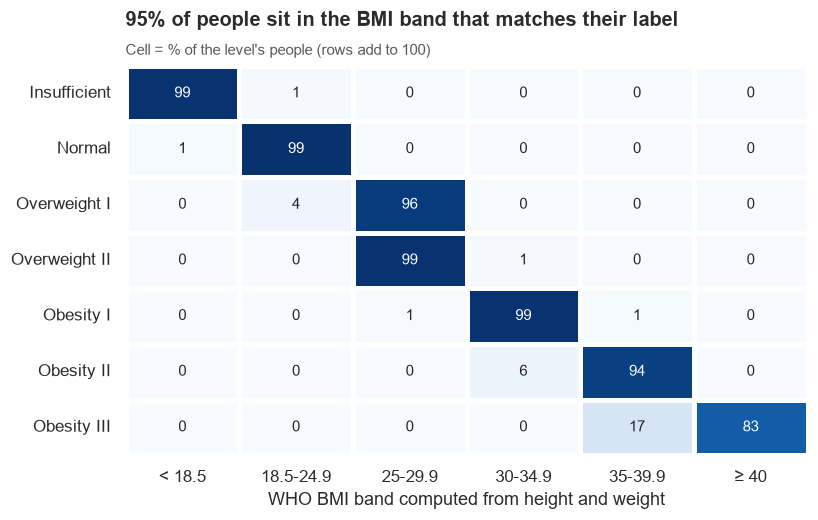

Agreement between label and the BMI band: 95.1%.


In [10]:
bands = pd.cut(df.bmi, [0, 18.5, 25, 30, 35, 40, 100], right=False,
               labels=["< 18.5", "18.5-24.9", "25-29.9", "30-34.9", "35-39.9", "≥ 40"])
tab = pd.crosstab(df.level, bands, normalize="index").reindex(LEVEL_ORDER) * 100

expected = {"Insufficient": "< 18.5", "Normal": "18.5-24.9", "Overweight I": "25-29.9", "Overweight II": "25-29.9",
            "Obesity I": "30-34.9", "Obesity II": "35-39.9", "Obesity III": "≥ 40"}
match = np.mean([str(b) == expected[l] for b, l in zip(bands, df.level)])

fig, ax = plt.subplots(figsize=(8, 4.6))
sns.heatmap(tab, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, cbar=False, ax=ax,
            linewidths=2, linecolor="white", annot_kws={"fontsize": 10})
ax.set_xlabel("WHO BMI band computed from height and weight")
ax.set_ylabel("")
ax.set_title(f"{match:.0%} of people sit in the BMI band that matches their label", pad=26)
subtitle(ax, "Cell = % of the level's people (rows add to 100)", y=1.02)
save(fig, "07_label_vs_bmi_band")
plt.show()
print(f"Agreement between label and the BMI band: {match:.1%}.")

**Consequence for the analysis.** Because the target is (almost) a function of height and weight, a model that sees them is trivially accurate. The interesting question is therefore different: *how much of the level can we tell from habits, age and gender alone?* We keep this question for sections 9-10.

### 5.3 Height and weight in one picture

Each dot is a person, coloured by level. The curved lines are fixed BMI values, so the colour bands follow them by construction.

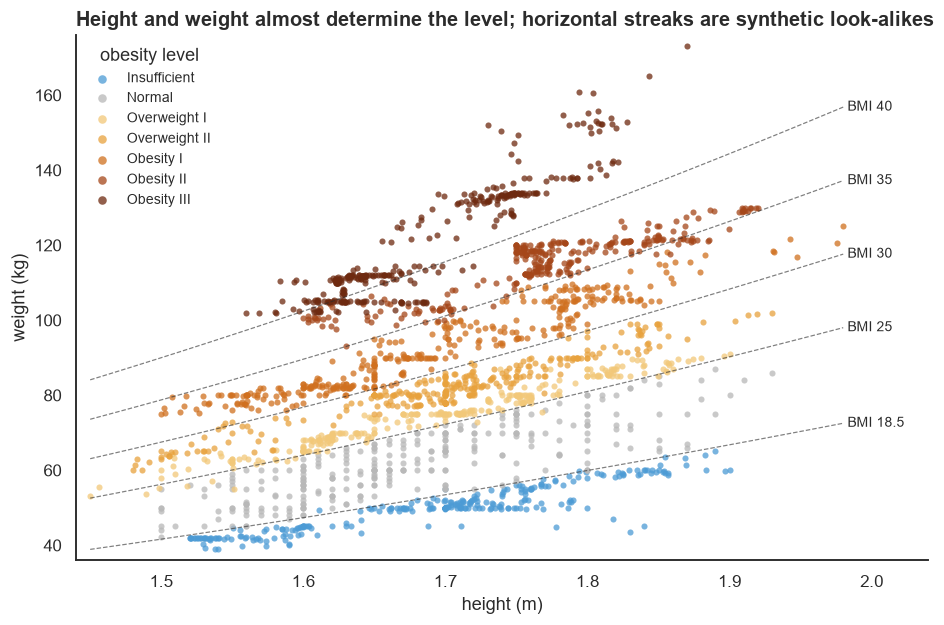

In [11]:
fig, ax = plt.subplots(figsize=(10, 6.2))
for lvl in LEVEL_ORDER:
    d = df[df.level == lvl]
    ax.scatter(d.height, d.weight, s=16, color=LEVEL_COLOR[lvl], alpha=0.75, linewidths=0, label=lvl)
h = np.linspace(df.height.min(), df.height.max(), 100)
for c in cuts:
    ax.plot(h, c * h**2, color=INK, lw=0.8, ls="--", alpha=0.6)
    ax.text(h[-1] + 0.003, c * h[-1]**2, f"BMI {c:g}", fontsize=9, va="center")
ax.set_xlim(df.height.min() - 0.01, df.height.max() + 0.06)
ax.set_ylim(df.weight.min() - 3, df.weight.max() + 3)
ax.set_xlabel("height (m)")
ax.set_ylabel("weight (kg)")
ax.legend(title="obesity level", loc="upper left", fontsize=9, ncol=1, markerscale=1.4)
ax.set_title("Height and weight almost determine the level; horizontal streaks are synthetic look-alikes")
save(fig, "08_height_weight")
plt.show()

## 6. Who is in each level?

### 6.1 Gender

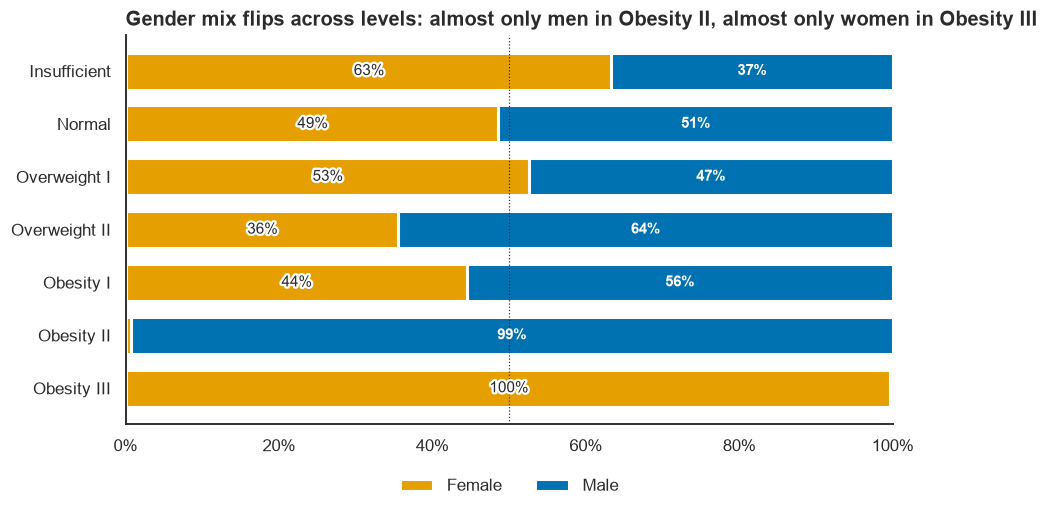

level,Insufficient,Normal,Overweight I,Overweight II,Obesity I,Obesity II,Obesity III
gender,,,,,,,
Female,169,137,145,103,156,2,323
Male,98,145,131,187,195,295,1


In [12]:
g = pd.crosstab(df.level, df.gender, normalize="index").reindex(LEVEL_ORDER) * 100
n_g = pd.crosstab(df.level, df.gender).reindex(LEVEL_ORDER)
fig, ax = plt.subplots(figsize=(9, 4.6))
y = np.arange(len(LEVEL_ORDER))[::-1]
ax.barh(y, g["Female"], color=ORANGE, height=0.7, edgecolor="white", linewidth=2, label="Female")
ax.barh(y, g["Male"], left=g["Female"], color=BLUE, height=0.7, edgecolor="white", linewidth=2, label="Male")
for yi, lvl in zip(y, LEVEL_ORDER):
    f, m = g.loc[lvl, "Female"], g.loc[lvl, "Male"]
    if f > 8: ax.text(f / 2, yi, f"{f:.0f}%", ha="center", va="center", fontsize=10, color=INK, path_effects=HALO)
    if m > 8: ax.text(f + m / 2, yi, f"{m:.0f}%", ha="center", va="center", fontsize=10, color="white", fontweight="bold")
ax.axvline(50, color=INK, lw=0.8, ls=":")
ax.set_yticks(y, LEVEL_ORDER)
ax.set_xlim(0, 100)
ax.xaxis.set_major_formatter(PercentFormatter(100))
ax.legend(ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.1))
ax.set_title("Gender mix flips across levels: almost only men in Obesity II, almost only women in Obesity III")
save(fig, "09_gender_by_level")
plt.show()
display(n_g.T)

This is a **feature of the sampling**, not a biological finding: Obesity III is almost only women, and Obesity II almost only men, which happens when synthetic rows are generated from a handful of real respondents. We report it as a warning about the data, and we keep gender as a control, not as an explanation.

### 6.2 Age

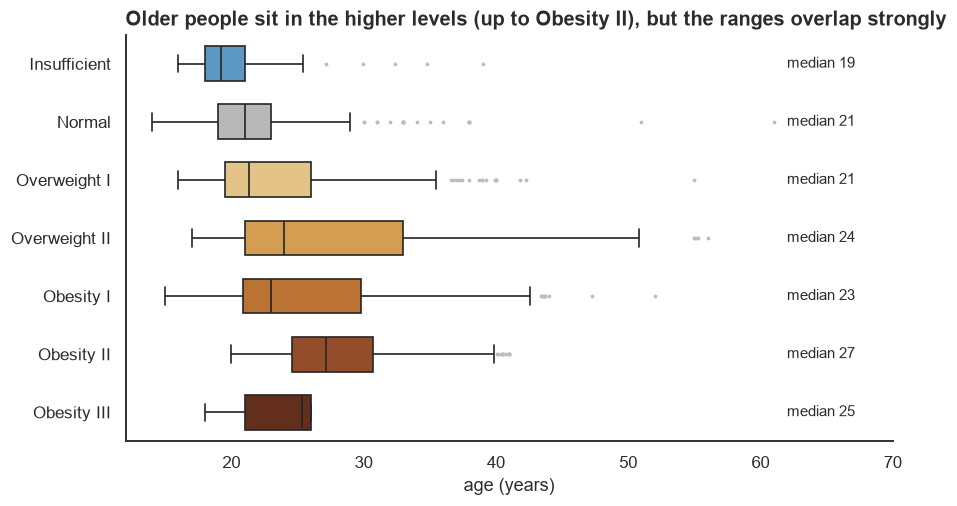

In [13]:
fig, ax = plt.subplots(figsize=(9, 4.8))
sns.boxplot(data=df, y="level", x="age", order=LEVEL_ORDER, palette=LEVEL_COLOR, ax=ax, width=0.6,
            fliersize=2.5, linewidth=1.1, flierprops=dict(markerfacecolor=GREY, markeredgecolor="none"))
for k, lvl in enumerate(LEVEL_ORDER):
    m = df.loc[df.level == lvl, "age"].median()
    ax.text(df.age.max() + 1, k, f"median {m:.0f}", va="center", fontsize=9.5)
ax.set_xlim(12, df.age.max() + 9)
ax.set_xlabel("age (years)")
ax.set_ylabel("")
ax.set_title("Older people sit in the higher levels (up to Obesity II), but the ranges overlap strongly")
save(fig, "10_age_by_level")
plt.show()

## 7. Habits and levels

### 7.1 Lifestyle scores by level

Each dot is the average code in a level, with its 95% confidence interval. The five panels share the level order, and each has its own x-range because the scales differ. If the dots do not move along the levels, the habit does not distinguish them.

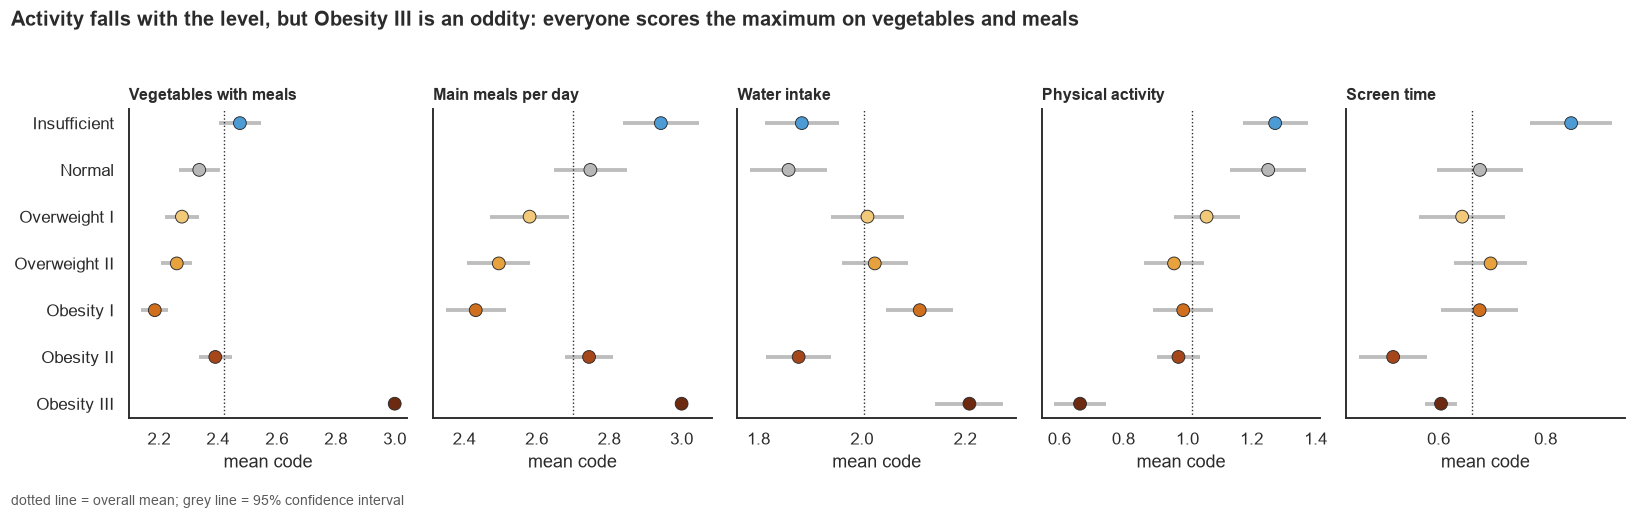

In [14]:
fig, axes = plt.subplots(1, 5, figsize=(15, 4.2), sharey=True)
for ax, c in zip(axes, ord_cols):
    m = df.groupby("level", observed=True)[c].agg(["mean", "sem"]).reindex(LEVEL_ORDER)
    y = np.arange(len(m))
    ax.hlines(y, m["mean"] - 1.96 * m["sem"], m["mean"] + 1.96 * m["sem"], color=GREY, lw=2.5)
    ax.scatter(m["mean"], y, color=[LEVEL_COLOR[l] for l in m.index], s=70, edgecolor=INK, linewidth=0.6, zorder=3)
    ax.axvline(df[c].mean(), color=INK, ls=":", lw=0.9)
    ax.set_title(lab[c].split("\n")[0], fontsize=10.5)
    ax.set_xlabel("mean code")
axes[0].set_yticks(range(len(LEVEL_ORDER)), LEVEL_ORDER)
axes[0].invert_yaxis()
fig.suptitle("Activity falls with the level, but Obesity III is an oddity: everyone scores the maximum on vegetables and meals",
             x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.04)
fig.text(0.01, -0.03, "dotted line = overall mean; grey line = 95% confidence interval", fontsize=9, color="#5A5A5A")
fig.tight_layout()
save(fig, "11_lifestyle_by_level")
plt.show()

### 7.2 How much more often are people in each habit group obese?

"Obese" here means the label is Obesity I, II or III (BMI of about 30 or more). For each category we show the share of obese people with a 95% Wilson confidence interval and the group size `n`. Wide intervals warn of small groups. The dashed line is the overall share.

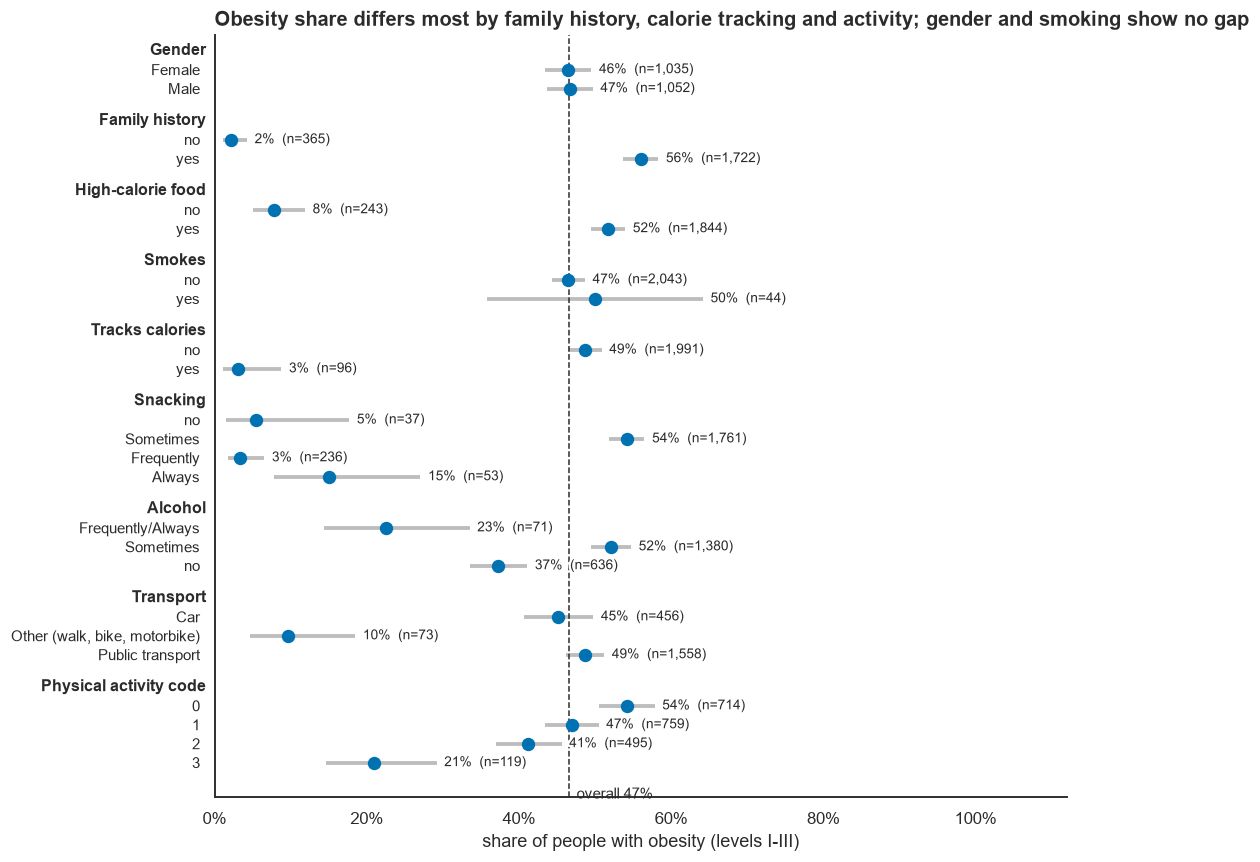

In [15]:
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

groups = [("Gender", "gender"), ("Family history", "family_history"), ("High-calorie food", "high_cal_food"),
          ("Smokes", "smoke"), ("Tracks calories", "track_calories"),
          ("Snacking", "snacking"), ("Alcohol", "alcohol_g"), ("Transport", "transport_g"),
          ("Physical activity code", "activity_r")]
rows = []
for title, c in groups:
    for val, d in df.groupby(c, observed=True):
        lo, hi = wilson(d.obese.sum(), len(d))
        rows.append({"group": title, "value": str(val), "share": d.obese.mean(), "lo": lo, "hi": hi, "n": len(d)})
res = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(10, 9))
ypos, yl, y = [], [], 0
for title, _ in groups:
    sub = res[res.group == title]
    ax.text(-0.01, y, title, transform=ax.get_yaxis_transform(), ha="right", va="center", fontweight="bold", fontsize=10.5)
    y += 1
    for _, r in sub.iterrows():
        ax.hlines(y, r.lo, r.hi, color=GREY, lw=2.5)
        ax.scatter(r.share, y, color=BLUE, s=60, zorder=3)
        ax.text(r.hi + 0.01, y, f"{r.share:.0%}  (n={r.n:,})", va="center", fontsize=9, path_effects=HALO)
        ypos.append(y); yl.append(r.value)
        y += 1
    y += 0.7
ax.set_yticks(ypos, yl, fontsize=9.5)
ax.invert_yaxis()
ax.axvline(df.obese.mean(), color=INK, ls="--", lw=1)
ax.text(df.obese.mean() + 0.01, y + 0.2, f"overall {df.obese.mean():.0%}", ha="left", fontsize=9.5)
ax.set_xlim(0, 1.12)
ax.xaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("share of people with obesity (levels I-III)")
ax.set_title("Obesity share differs most by family history, calorie tracking and activity; gender and smoking show no gap")
save(fig, "12_obesity_share_by_group")
plt.show()

### 7.3 Two habits together

Eating high-calorie food and being physically inactive are often discussed together. We split the share of obesity by both.

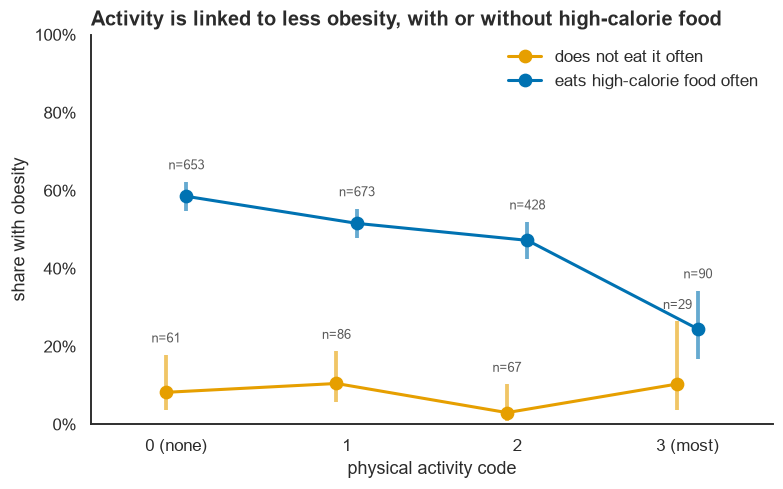

In [16]:
t = (df.groupby(["activity_r", "high_cal_food"]).obese.agg(["mean", "sum", "count"]).reset_index())
t["lo"], t["hi"] = zip(*[wilson(k, n) for k, n in zip(t["sum"], t["count"])])

fig, ax = plt.subplots(figsize=(8, 4.6))
for val, col, dx in [("no", ORANGE, -0.06), ("yes", BLUE, 0.06)]:
    d = t[t.high_cal_food == val]
    ax.vlines(d.activity_r + dx, d.lo, d.hi, color=col, lw=2.5, alpha=0.6)
    ax.plot(d.activity_r + dx, d["mean"], color=col, lw=2, marker="o", markersize=8,
            label="eats high-calorie food often" if val == "yes" else "does not eat it often")
    for _, r in d.iterrows():
        ax.text(r.activity_r + dx, r.hi + 0.025, f"n={r['count']}", ha="center", va="bottom", fontsize=8.5, color="#5A5A5A")
ax.set_xticks([0, 1, 2, 3], ["0 (none)", "1", "2", "3 (most)"])
ax.set_xlim(-0.5, 3.5)
ax.set_ylim(0, 1)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_xlabel("physical activity code")
ax.set_ylabel("share with obesity")
ax.legend(loc="upper right")
ax.set_title("Activity is linked to less obesity, with or without high-calorie food")
save(fig, "13_activity_x_food")
plt.show()

## 8. Relationships between all variables

### 8.1 Numeric variables (Spearman correlation)

Rank correlation is used because the lifestyle scores are ordinal. Colour: blue = negative, orange = positive, grey/white = none. Only the lower triangle is shown, because the upper triangle repeats it.

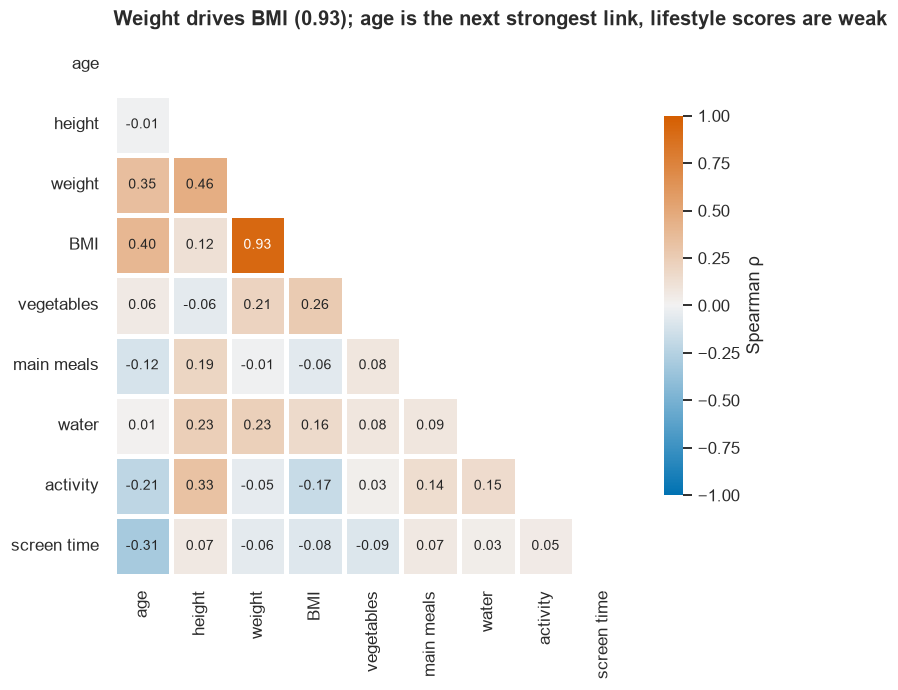

In [17]:
num = ["age", "height", "weight", "bmi"] + ord_cols
names = ["age", "height", "weight", "BMI", "vegetables", "main meals", "water", "activity", "screen time"]
corr = df[num].corr(method="spearman")
corr.index = corr.columns = names
mask = np.triu(np.ones_like(corr, dtype=bool), k=0)
div = LinearSegmentedColormap.from_list("div", [BLUE, "#F2F2F2", "#D55E00"])

fig, ax = plt.subplots(figsize=(7.6, 6.4))
sns.heatmap(corr, mask=mask, cmap=div, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f", ax=ax,
            linewidths=2, linecolor="white", cbar_kws={"shrink": 0.7, "label": "Spearman ρ"},
            annot_kws={"fontsize": 9})
ax.set_title("Weight drives BMI (0.93); age is the next strongest link, lifestyle scores are weak")
save(fig, "14_spearman")
plt.show()

### 8.2 Categorical variables and the level (Cramér's V)

Cramér's V (bias-corrected) measures association between two categorical variables from 0 (none) to 1 (perfect). One colour, light to dark, because the scale has no direction.

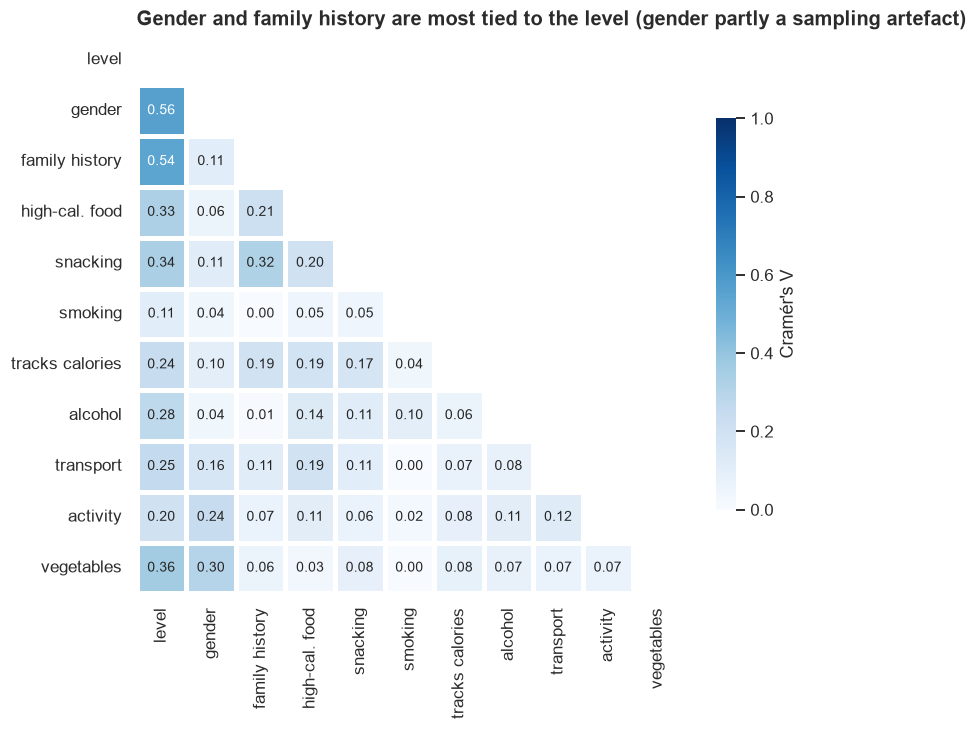

gender             0.56
family history     0.54
vegetables         0.36
snacking           0.34
high-cal. food     0.33
alcohol            0.28
transport          0.25
tracks calories    0.24
activity           0.20
smoking            0.11


In [18]:
def cramers_v(a, b):
    t = pd.crosstab(a, b)
    chi2 = stats.chi2_contingency(t, correction=False)[0]
    n = t.values.sum()
    phi2 = max(0, chi2 / n - (t.shape[0] - 1) * (t.shape[1] - 1) / (n - 1))
    r = t.shape[0] - (t.shape[0] - 1) ** 2 / (n - 1)
    k = t.shape[1] - (t.shape[1] - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / max(min(r, k) - 1, 1e-9))

cv = {"level": "level", "gender": "gender", "family_history": "family history", "high_cal_food": "high-cal. food",
      "snacking": "snacking", "smoke": "smoking", "track_calories": "tracks calories", "alcohol_g": "alcohol",
      "transport_g": "transport", "activity_r": "activity", "veg_freq_r": "vegetables"}
cols = list(cv)
V = pd.DataFrame([[cramers_v(df[a].astype(str), df[b].astype(str)) for b in cols] for a in cols],
                 index=list(cv.values()), columns=list(cv.values()))
mask = np.triu(np.ones_like(V, dtype=bool), k=0)
fig, ax = plt.subplots(figsize=(8, 6.6))
sns.heatmap(V, mask=mask, cmap="Blues", vmin=0, vmax=1, annot=True, fmt=".2f", ax=ax,
            linewidths=2, linecolor="white", cbar_kws={"shrink": 0.7, "label": "Cramér's V"}, annot_kws={"fontsize": 9})
ax.set_title("Gender and family history are most tied to the level (gender partly a sampling artefact)")
save(fig, "15_cramers_v")
plt.show()
print(V["level"].drop("level").sort_values(ascending=False).round(2).to_string())

## 9. The whole picture: do people with similar habits look similar?

We now treat each person as a point in a space of mixed variables (numbers and categories). The **Gower distance** handles both kinds: numbers use the range-scaled absolute difference, categories use "same or different". We then draw it in 2D with **t-SNE**, which keeps close neighbours close.

Two maps are compared:

* **All features** (including height and weight): we expect clear structure by level.
* **Lifestyle only** (age, gender, habits; no height, weight or BMI): the question is whether habits alone place similar levels together.

To give a number instead of an impression we compute the **neighbour agreement**: the average share of a person's 15 nearest neighbours that have the same level. Chance level is the sum of squared class shares, around 14%.

In [19]:
def gower(data, num_cols, cat_cols):
    n = len(data)
    D = np.zeros((n, n), dtype=np.float32)
    for c in num_cols:
        x = data[c].to_numpy(float)
        D += np.abs(x[:, None] - x[None, :]) / (np.ptp(x) or 1)
    for c in cat_cols:
        x = pd.factorize(data[c].astype(str))[0]
        D += (x[:, None] != x[None, :])
    return D / (len(num_cols) + len(cat_cols))

CAT = ["gender", "family_history", "high_cal_food", "snacking", "smoke", "track_calories", "alcohol", "transport"]
NUM_LIFE = ["age"] + ord_cols
sets = {"All features (with height and weight)": (["height", "weight"] + NUM_LIFE, CAT),
        "Lifestyle only (no height, weight, BMI)": (NUM_LIFE, CAT)}

lab_codes = df.level.cat.codes.to_numpy()
chance = float((df.level.value_counts(normalize=True) ** 2).sum())

def neighbour_agreement(D, k=15):
    nn = NearestNeighbors(n_neighbors=k + 1, metric="precomputed").fit(D)
    idx = nn.kneighbors(D, return_distance=False)[:, 1:]
    return float((lab_codes[idx] == lab_codes[:, None]).mean())

emb, agree = {}, {}
for name, (nc, cc) in sets.items():
    D = gower(df, nc, cc)
    agree[name] = neighbour_agreement(D)
    emb[name] = TSNE(2, metric="precomputed", init="random", perplexity=40, random_state=SEED).fit_transform(D)
    print(f"{name}: neighbour agreement {agree[name]:.0%} (chance {chance:.0%})")

All features (with height and weight): neighbour agreement 70% (chance 14%)
Lifestyle only (no height, weight, BMI): neighbour agreement 63% (chance 14%)


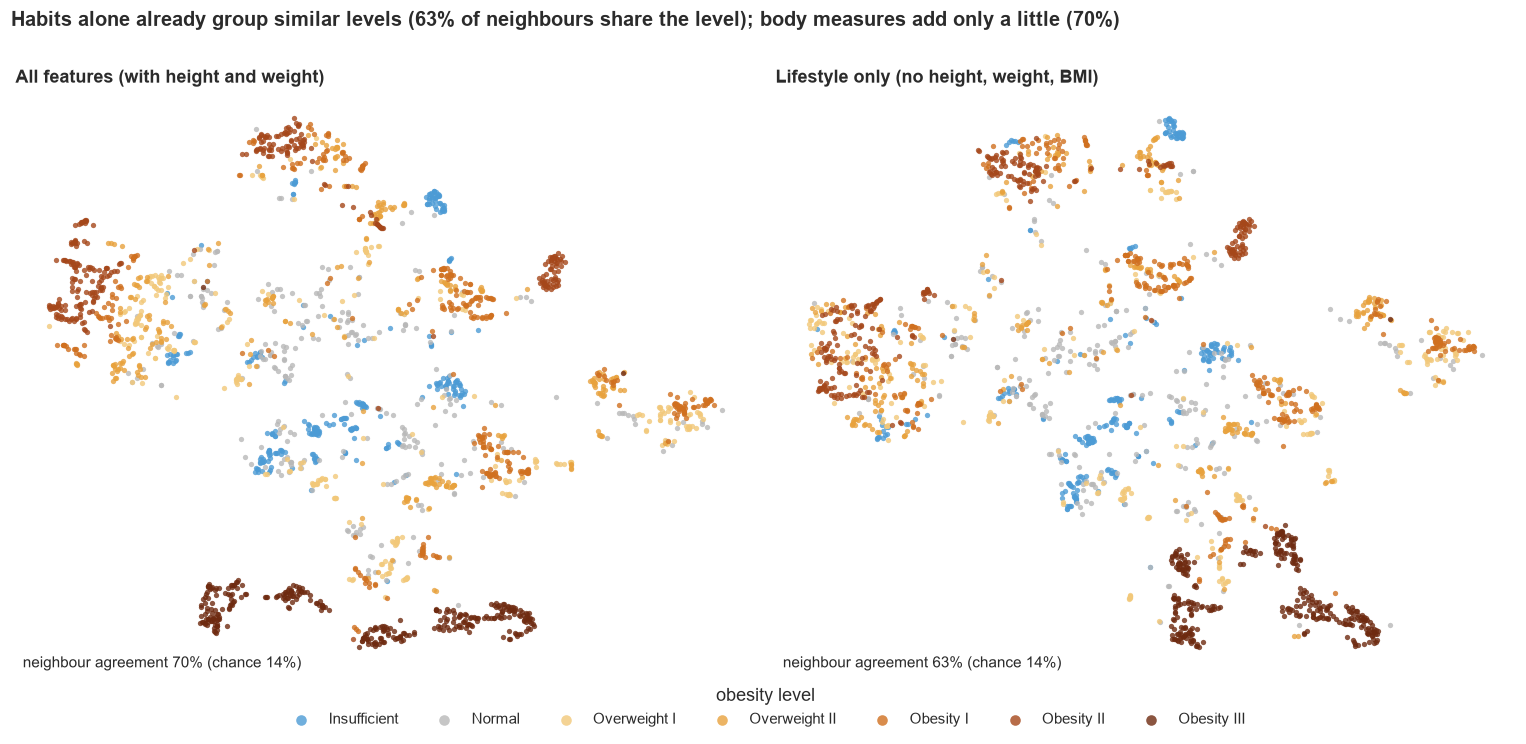

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6.2))
for ax, (name, xy) in zip(axes, emb.items()):
    for lvl in LEVEL_ORDER:
        m = (df.level == lvl).to_numpy()
        ax.scatter(xy[m, 0], xy[m, 1], s=12, color=LEVEL_COLOR[lvl], alpha=0.8, linewidths=0, label=lvl)
    ax.set_title(name, fontsize=11.5)
    ax.text(0.01, 0.01, f"neighbour agreement {agree[name]:.0%} (chance {chance:.0%})", transform=ax.transAxes,
            fontsize=10, path_effects=HALO)
    ax.axis("off")
h, l = axes[0].get_legend_handles_labels()
fig.legend(h, l, title="obesity level", loc="lower center", ncol=7, markerscale=2, fontsize=10, bbox_to_anchor=(0.5, -0.07))
k0, k1 = list(agree.values())
fig.suptitle(f"Habits alone already group similar levels ({k1:.0%} of neighbours share the level); body measures add only a little ({k0:.0%})",
             x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.0)
fig.tight_layout()
save(fig, "16_tsne_comparison")
plt.show()

## 10. How well can the level be predicted?

A random forest predicts the seven levels from three different sets of inputs, using 5-fold cross-validation:

1. **Height and weight only** (the label's own ingredients);
2. **Lifestyle + age + gender** (no body measures);
3. **Everything.**

We report the **exact accuracy** and the accuracy **within one level** (counting a neighbouring level as nearly right, which suits an ordered target). The dotted line is guessing the most common level.

> **Caveat.** Synthetic rows are interpolations of real ones, so a synthetic row and its "parent" can land in different folds. This makes every score optimistic, especially for the model that sees many features. Compare the *differences* between the three sets, not the absolute values.

In [21]:
X_cat = pd.get_dummies(df[CAT].astype(str), drop_first=True)
feature_sets = {
    "Height and weight only": df[["height", "weight"]],
    "Lifestyle + age + gender": pd.concat([df[NUM_LIFE], X_cat], axis=1),
    "Everything": pd.concat([df[["height", "weight"] + NUM_LIFE], X_cat], axis=1),
}
y = df.level.cat.codes.to_numpy()
skf = StratifiedKFold(5, shuffle=True, random_state=SEED)
rf = lambda: RandomForestClassifier(300, min_samples_leaf=2, n_jobs=-1, random_state=SEED)

acc, preds = {}, {}
for name, X in feature_sets.items():
    p = cross_val_predict(rf(), X, y, cv=skf)
    preds[name] = p
    acc[name] = {"exact": (p == y).mean(), "within one level": (np.abs(p - y) <= 1).mean()}
acc = pd.DataFrame(acc).T
display((acc * 100).round(1))
baseline = df.level.value_counts(normalize=True).max()

,exact,within one level
Height and weight only,96.4,100.0
Lifestyle + age + gender,85.1,92.5
Everything,94.3,98.5


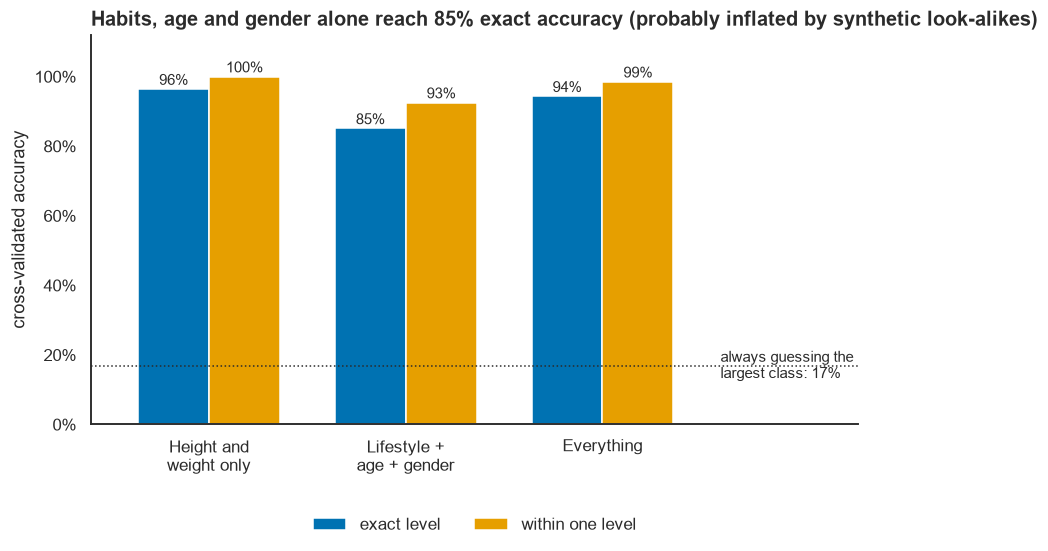

In [22]:
fig, ax = plt.subplots(figsize=(9, 4.6))
x = np.arange(len(acc))
w = 0.36
b1 = ax.bar(x - w / 2, acc["exact"], w, color=BLUE, label="exact level")
b2 = ax.bar(x + w / 2, acc["within one level"], w, color=ORANGE, label="within one level")
for b in list(b1) + list(b2):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.012, f"{b.get_height():.0%}", ha="center", fontsize=10)
ax.axhline(baseline, color=INK, ls=":", lw=1)
ax.text(len(acc) - 0.4, baseline, f"always guessing the\nlargest class: {baseline:.0%}", ha="left", va="center", fontsize=9.5)
ax.set_xlim(-0.6, len(acc) + 0.3)
ax.set_xticks(x, [i.replace(" and ", " and\n").replace("+ age", "+ age\n").replace(" + age\n + gender", " +\nage + gender") for i in acc.index])
ax.set_ylim(0, 1.12)
ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
ax.set_ylabel("cross-validated accuracy")
ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.2))
ax.set_title(f"Habits, age and gender alone reach {acc.loc['Lifestyle + age + gender', 'exact']:.0%} exact accuracy (probably inflated by synthetic look-alikes)")
save(fig, "17_model_accuracy")
plt.show()

### 10.1 Where does the lifestyle model go wrong, and what does it use?

The confusion matrix shows, for each true level, where its people end up (rows add to 100%). Errors close to the diagonal are the "near misses". Permutation importance (on a held-out 25%) shows how much accuracy drops when one input is shuffled.

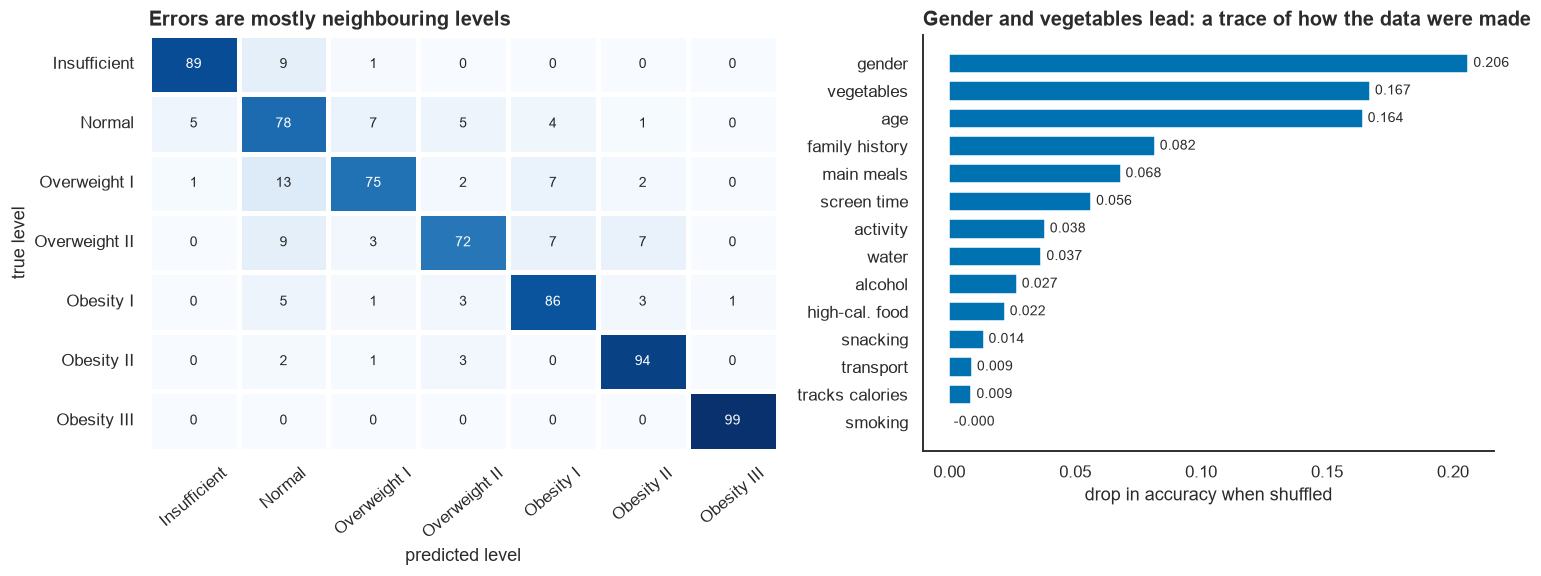

In [23]:
name = "Lifestyle + age + gender"
cm = confusion_matrix(y, preds[name], normalize="true") * 100
fig, ax = plt.subplots(1, 2, figsize=(14, 5.4), gridspec_kw={"width_ratios": [1.1, 1]})

sns.heatmap(cm, annot=True, fmt=".0f", cmap="Blues", vmin=0, vmax=100, cbar=False, ax=ax[0],
            xticklabels=LEVEL_ORDER, yticklabels=LEVEL_ORDER, linewidths=2, linecolor="white", annot_kws={"fontsize": 9})
ax[0].set_xlabel("predicted level")
ax[0].set_ylabel("true level")
ax[0].tick_params(axis="x", rotation=40)
ax[0].set_title("Errors are mostly neighbouring levels")

X = feature_sets[name]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, stratify=y, random_state=SEED)
model = rf().fit(Xtr, ytr)
pi = permutation_importance(model, Xte, yte, n_repeats=10, random_state=SEED, n_jobs=-1)
imp = pd.Series(pi.importances_mean, index=X.columns)
# add dummy columns back to their variable
var = imp.groupby(lambda c: next((v for v in CAT if c.startswith(v + "_")), c)).sum().sort_values()
pretty = {"age": "age", "veg_freq": "vegetables", "main_meals": "main meals", "water": "water", "activity": "activity",
          "screen_time": "screen time", "gender": "gender", "family_history": "family history",
          "high_cal_food": "high-cal. food", "snacking": "snacking", "smoke": "smoking",
          "track_calories": "tracks calories", "alcohol": "alcohol", "transport": "transport"}
ax[1].barh([pretty[i] for i in var.index], var.values, color=BLUE, height=0.7)
for yy, v in enumerate(var.values):
    ax[1].text(v + 0.002, yy, f"{v:.3f}", va="center", fontsize=9)
ax[1].set_xlabel("drop in accuracy when shuffled")
ax[1].set_title("Gender and vegetables lead: a trace of how the data were made")
fig.tight_layout()
save(fig, "18_confusion_importance")
plt.show()

## 11. Hypotheses and effect sizes

We state three hypotheses before looking at the tests and report **effect sizes with confidence intervals**, not only p-values. With 2,000 people almost any difference is "significant", so the size of the effect is what matters. The synthetic origin of most rows means the intervals are optimistic (rows are not independent), so they are guides, not guarantees.

* **H1.** People who often eat high-calorie food have a higher BMI.
* **H2.** More physical activity goes with a lower BMI.
* **H3.** A family history of overweight goes with a higher BMI.

For two-group questions: difference in median BMI with a 95% bootstrap interval. For ordinal scores and age: Spearman correlation with BMI and a bootstrap interval.

In [24]:
def boot_median_diff(a, b, n=2000):
    a, b = np.asarray(a), np.asarray(b)
    d = [np.median(rng.choice(a, len(a))) - np.median(rng.choice(b, len(b))) for _ in range(n)]
    return np.median(a) - np.median(b), np.percentile(d, [2.5, 97.5])

binary = [("H3  Family history of overweight", "family_history", "yes", "no"),
          ("H1  Eats high-calorie food often", "high_cal_food", "yes", "no"),
          ("Smokes", "smoke", "yes", "no"),
          ("Tracks calories", "track_calories", "yes", "no"),
          ("Male (vs female)", "gender", "Male", "Female")]
rows = []
for label, c, a, b in binary:
    A, B = df.loc[df[c] == a, "bmi"], df.loc[df[c] == b, "bmi"]
    diff, (lo, hi) = boot_median_diff(A, B)
    p = stats.mannwhitneyu(A, B).pvalue
    rows.append({"label": label, "diff": diff, "lo": lo, "hi": hi, "p": p, "n": f"{len(A)} vs {len(B)}"})
bin_res = pd.DataFrame(rows)
bin_res["p_holm"] = np.minimum(1, bin_res.p.rank(method="first").pipe(lambda r: (len(r) - r + 1)) * bin_res.p)  # approx. Holm (ordered below)
order = bin_res.p.argsort().to_numpy()
holm = np.empty(len(bin_res))
run = 0
for rank, i in enumerate(order):
    run = max(run, min(1, (len(bin_res) - rank) * bin_res.p[i]))
    holm[i] = run
bin_res["p_holm"] = holm

def boot_spearman(x, y_, n=1000):
    x, y_ = np.asarray(x), np.asarray(y_)
    out = []
    for _ in range(n):
        i = rng.integers(0, len(x), len(x))
        out.append(stats.spearmanr(x[i], y_[i])[0])
    return stats.spearmanr(x, y_)[0], np.percentile(out, [2.5, 97.5])

cont = [("H2  Physical activity", "activity"), ("Vegetables with meals", "veg_freq"), ("Main meals", "main_meals"),
        ("Water intake", "water"), ("Screen time", "screen_time"), ("Age", "age")]
rows = []
for label, c in cont:
    r, (lo, hi) = boot_spearman(df[c], df.bmi)
    rows.append({"label": label, "rho": r, "lo": lo, "hi": hi})
cont_res = pd.DataFrame(rows)

display(bin_res.assign(p=lambda d: d.p.map("{:.1e}".format), p_holm=lambda d: d.p_holm.map("{:.1e}".format))[["label", "n", "diff", "lo", "hi", "p", "p_holm"]].round(2))
display(cont_res.round(2))

,label,n,diff,lo,hi,p,p_holm
0,H3 Family history of overweight,1722 vs 365,10.65,9.85,11.88,2.2e-114,1.1e-113
1,H1 Eats high-calorie food often,1844 vs 243,6.42,4.48,7.30,1.7e-30,7.0e-30
2,Smokes,44 vs 2043,0.80,-2.15,4.74,9.7e-01,9.7e-01
3,Tracks calories,96 vs 1991,-5.19,-7.47,-4.28,1.5e-20,4.6e-20
4,Male (vs female),1052 vs 1035,0.38,-0.70,1.57,3.4e-01,6.9e-01


,label,rho,lo,hi
0,H2 Physical activity,-0.17,-0.22,-0.13
1,Vegetables with meals,0.26,0.22,0.31
2,Main meals,-0.06,-0.11,-0.02
3,Water intake,0.16,0.12,0.20
4,Screen time,-0.08,-0.12,-0.04
5,Age,0.40,0.36,0.43


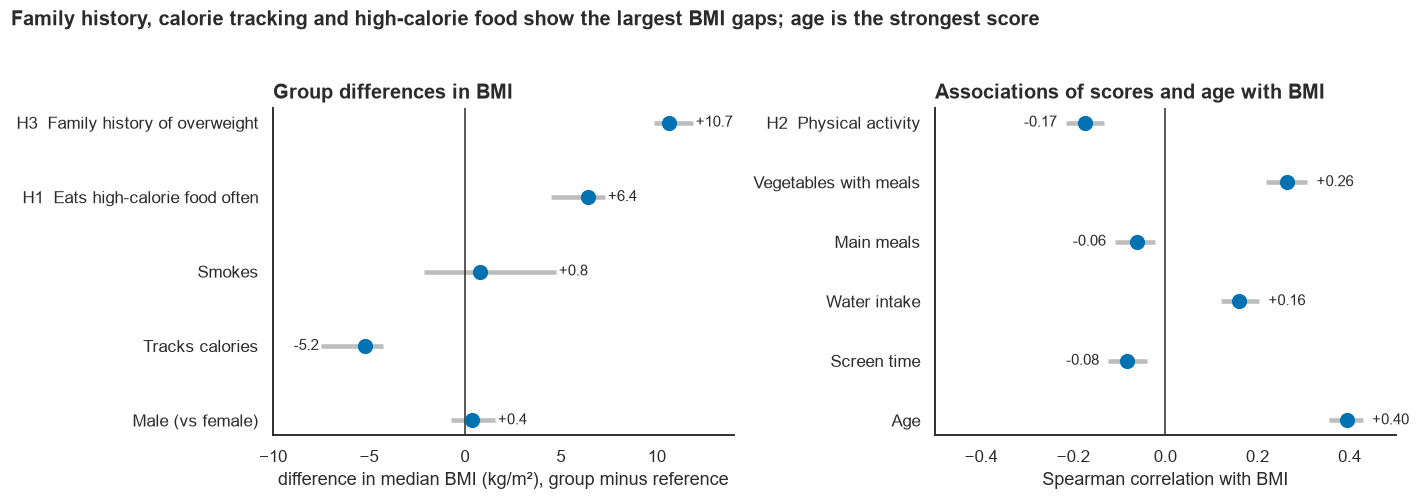

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1, 1]})

d = bin_res.iloc[::-1]
yy = np.arange(len(d))
ax[0].hlines(yy, d.lo, d.hi, color=GREY, lw=3)
ax[0].scatter(d["diff"], yy, color=BLUE, s=80, zorder=3)
for y_, r in zip(yy, d.itertuples()):
    (ax[0].text(r.hi + 0.15, y_, f"{r.diff:+.1f}", va="center", fontsize=10) if r.diff >= 0 else
     ax[0].text(r.lo - 0.15, y_, f"{r.diff:+.1f}", va="center", ha="right", fontsize=10))
ax[0].axvline(0, color=INK, lw=1)
ax[0].set_yticks(yy, d.label)
ax[0].set_xlabel("difference in median BMI (kg/m²), group minus reference")
ax[0].set_xlim(-10, 14)
ax[0].set_title("Group differences in BMI")

d = cont_res.iloc[::-1]
yy = np.arange(len(d))
ax[1].hlines(yy, d.lo, d.hi, color=GREY, lw=3)
ax[1].scatter(d.rho, yy, color=BLUE, s=80, zorder=3)
for y_, r in zip(yy, d.itertuples()):
    (ax[1].text(r.hi + 0.02, y_, f"{r.rho:+.2f}", va="center", fontsize=10) if r.rho >= 0 else
     ax[1].text(r.lo - 0.02, y_, f"{r.rho:+.2f}", va="center", ha="right", fontsize=10))
ax[1].axvline(0, color=INK, lw=1)
ax[1].set_yticks(yy, d.label)
ax[1].set_xlim(-0.5, 0.5)
ax[1].set_xlabel("Spearman correlation with BMI")
ax[1].set_title("Associations of scores and age with BMI")
fig.suptitle("Family history, calorie tracking and high-calorie food show the largest BMI gaps; age is the strongest score",
             x=0.01, ha="left", fontsize=13, fontweight="bold", y=1.03)
fig.tight_layout()
save(fig, "19_effect_sizes")
plt.show()

## 12. Interactive exploration

Hover over a point for the person's details; click a level in the legend to hide or show it. This is for exploring, the static figures above are for the presentation.

In [26]:
fig = go.Figure()
for lvl in LEVEL_ORDER:
    d = df[df.level == lvl]
    fig.add_trace(go.Scattergl(
        x=d.age, y=d.bmi, mode="markers", name=lvl,
        marker=dict(size=6, color=LEVEL_COLOR[lvl], opacity=0.75),
        text=[f"{lvl}<br>age {a:.0f}, BMI {b:.1f}<br>activity {f:.1f}, vegetables {v:.1f}<br>{g}, transport: {t}"
              for a, b, f, v, g, t in zip(d.age, d.bmi, d.activity, d.veg_freq, d.gender, d.transport)],
        hoverinfo="text"))
for c in cuts:
    fig.add_hline(y=c, line_dash="dot", line_color=INK, opacity=0.4)
fig.update_layout(template="simple_white", height=560, width=950, title="BMI against age (click the legend to filter levels)",
                  xaxis_title="age (years)", yaxis_title="BMI (kg/m²)", legend_title="obesity level")
fig.write_html(FIG_DIR / "20_interactive_age_bmi.html")
show_plotly(fig)

## 13. Conclusions

**1. What the data is.** 2,111 rows, no missing values, 24 duplicates (removed, 2,087 remain). 30-65% of the "ordinal" and age values are not whole numbers, which fits the UCI statement that 77% of the rows are synthetic. The seven levels are almost equally common (about 270-350 people each), so the class sizes say nothing about real prevalence. The sample is young (83% under 30).

**2. The target is BMI in disguise.** 95% of people sit in the WHO BMI band that matches their label, so height and weight "explain" the level by construction (a random forest on height and weight alone reaches 96% exact accuracy). This is why the interesting question is what habits, age and gender add *without* body measures.

**3. What habits say.**
* **Activity** falls with the level (the share of obese people drops from 54% at activity code 0 to 21% at code 3) and has a small negative rank correlation with BMI (ρ = -0.17).
* **Eating high-calorie food** (H1): median BMI is 6.4 points higher (95% interval 4.5 to 7.3) and 52% vs 8% are obese.
* **Family history** (H3): median BMI is 10.7 points higher (9.9 to 11.9); 56% vs 2% are obese. This gap is unusually large and is probably exaggerated by how the synthetic rows were generated.
* **Physical activity** (H2): supported but modest (ρ = -0.17).
* **Gender and smoking** show no BMI gap (+0.4 and +0.8, intervals include 0).
* **Age** is the strongest lifestyle-side link (ρ = +0.40).
* Some patterns are **not plausible as real effects**: more vegetables go with *higher* BMI (ρ = +0.26), and people who snack "frequently" are rarely obese (3%) while those who snack "sometimes" often are (54%). Obesity III has the maximum vegetable and meal scores for almost everyone. These are the fingerprints of synthetic generation from a few real respondents.

**4. Do similar habits mean similar levels?** In the Gower-distance t-SNE, 63% of a person's 15 nearest neighbours share the level using habits, age and gender alone, against 70% when height and weight are added (chance is 14%). A random forest on habits alone reaches 85% exact and 93% within-one-level accuracy (cross-validated). Both numbers are very likely inflated, because synthetic rows are copies-with-noise of real rows and can sit in different folds. The model relies mainly on gender, vegetables and age, which are exactly the variables where the data generation left its mark.

### Limitations to state honestly

* **Mostly synthetic data (77%)** and no flag for which rows are real: confidence intervals and cross-validated scores are optimistic because rows are not independent.
* **Balanced classes by construction**, so prevalence and class-conditional shares cannot be generalised.
* **Label derived from BMI**: obesity level cannot be used as an independent outcome for "explaining" with height and weight.
* **Self-reported habits**, coded as ordinal scores; the exact meaning of some codes (for example main meals, 1-4) is not documented in the file.
* **Young Latin American sample** (Mexico, Peru, Colombia), 83% under 30; not representative of other populations.
* **Association is not causation**; habits may be a consequence of weight as well as a cause.
* **Several results look like artefacts** (gender split in Obesity II/III, vegetables, snacking); we report them as warnings about the data, not as findings about people.

## 14. Suggested 20-minute storyboard

| min | Message | Figures |
|---|---|---|
| 0-2 | Hook: obesity is measured by BMI, but is it explained by habits? | `08_height_weight` |
| 2-5 | The data: partly synthetic, balanced by construction | `01_synthetic_fingerprint`, `05_class_balance` |
| 5-8 | The label is BMI: why height and weight must be removed | `06_bmi_by_level`, `07_label_vs_bmi_band` |
| 8-12 | Who and what: age, gender, habits by level | `10_age_by_level`, `11_lifestyle_by_level`, `12_obesity_share_by_group` |
| 12-15 | Relationships | `14_spearman`, `15_cramers_v` |
| 15-18 | Do similar habits mean similar levels? | `16_tsne_comparison`, `17_model_accuracy`, `18_confusion_importance` |
| 18-20 | Effect sizes, limitations, conclusion | `19_effect_sizes` |